# 03 - Class imbalance and feature selection

Notebook 02 showed that every important error is **Bot predicted as BENIGN**
(XGBoost misses about 20% of Bot flows). This notebook asks three questions:

1. **Imbalance:** do class weights or SMOTE raise Bot detection, and at what cost
   in false alarms?
2. **Feature selection:** how few features do we need without losing
   performance? (Small feature sets matter for lightweight / IoT detectors.)
3. **Shortcut check:** does the model depend on `Destination Port`?

**Protocol (to avoid fooling ourselves).** We use the *same* 80/20 split as
notebook 02. All choices (which imbalance strategy, which features) are made
using the **training set only**, with 5-fold cross-validation. The test set is
used once per configuration, for reporting.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler, FunctionTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import f1_score, precision_recall_fscore_support, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_sample_weight
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

sys.path.insert(0, str(Path.cwd().parent))
from src.data import feature_columns, LABEL_COL, PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

## 1. Data and the same split as notebook 02

In [2]:
df = pd.read_parquet(PROCESSED_DIR / "friday_clean.parquet")
feats = feature_columns(df)
encoder = LabelEncoder()
y = encoder.fit_transform(df[LABEL_COL])
classes = list(encoder.classes_)
BOT = classes.index("Bot")

X_train, X_test, y_train, y_test = train_test_split(
    df[feats], y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("train:", X_train.shape, " test:", X_test.shape, " Bot in test:", int((y_test == BOT).sum()))

train: (492346, 67)  test: (123087, 67)  Bot in test: 389


## 2. Helpers

`evaluate` reports what matters for a rare attack class:

- **bot_recall**: share of real Bot flows we catch.
- **bot_precision**: share of Bot alarms that are really Bot.
- **false_bot_alarms**: benign flows wrongly flagged as Bot (the cost of higher recall).

In [3]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))


def make_xgb():
    return XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1,
                         tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)


def make_rf(class_weight=None):
    return RandomForestClassifier(n_estimators=100, class_weight=class_weight,
                                  n_jobs=-1, random_state=RANDOM_STATE)


def make_smote_xgb(n_bot=20_000):
    # SMOTE works with distances, so put features on a comparable scale first.
    # Trees are not affected by these monotonic transforms.
    return ImbPipeline([
        ("log", FunctionTransformer(signed_log)),
        ("scale", StandardScaler()),
        ("smote", SMOTE(sampling_strategy={BOT: n_bot}, random_state=RANDOM_STATE)),
        ("model", make_xgb()),
    ])


# name -> (function that builds a fresh model, use balanced sample weights?)
STRATEGIES = {
    "XGB, no handling":   (make_xgb, False),
    "XGB, class weights": (make_xgb, True),
    "XGB, SMOTE":         (make_smote_xgb, False),
    "RF, no handling":    (make_rf, False),
    "RF, class weights":  (lambda: make_rf("balanced_subsample"), False),
}


def fit(build, weighted, X, y):
    model = build()
    if weighted:
        model.fit(X, y, sample_weight=compute_sample_weight("balanced", y))
    else:
        model.fit(X, y)
    return model


def evaluate(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[BOT], zero_division=0)
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "bot_precision": p[0],
        "bot_recall": r[0],
        "bot_f1": f[0],
        "bot_missed": int(((y_true == BOT) & (y_pred != BOT)).sum()),
        "false_bot_alarms": int(((y_true != BOT) & (y_pred == BOT)).sum()),
    }

## 3. Imbalance strategies (5-fold CV on the training set)

Each strategy is trained 5 times on 4/5 of the training data and scored on the
remaining 1/5. We report mean +/- standard deviation, so we can tell a real
improvement from noise. This takes several minutes.

In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, (build, weighted) in STRATEGIES.items():
    t0 = time.perf_counter()
    for fold, (tr, va) in enumerate(skf.split(X_train, y_train)):
        model = fit(build, weighted, X_train.iloc[tr], y_train[tr])
        cv_rows.append({"strategy": name, "fold": fold,
                        **evaluate(y_train[va], model.predict(X_train.iloc[va]))})
    print(f"{name:20s} done in {time.perf_counter() - t0:.0f}s")

cv = pd.DataFrame(cv_rows)
metrics = ["macro_f1", "bot_precision", "bot_recall", "bot_f1", "bot_missed", "false_bot_alarms"]
cv_summary = cv.groupby("strategy")[metrics].agg(["mean", "std"])
cv_summary = cv_summary.reindex(STRATEGIES.keys())
cv_summary.round(4)

XGB, no handling     done in 116s


XGB, class weights   done in 398s


XGB, SMOTE           done in 601s


RF, no handling      done in 88s


RF, class weights    done in 47s


macro_f1         bot_precision         bot_recall          \
                       mean     std          mean     std       mean     std   
strategy                                                                       
XGB, no handling     0.9606  0.0030        0.8673  0.0247     0.8223  0.0305   
XGB, class weights   0.9584  0.0029        0.7516  0.0186     0.9391  0.0158   
XGB, SMOTE           0.9560  0.0038        0.7335  0.0205     0.9429  0.0083   
RF, no handling      0.9565  0.0050        0.8791  0.0217     0.7813  0.0268   
RF, class weights    0.9594  0.0054        0.8924  0.0267     0.7922  0.0328   

                    bot_f1         bot_missed          false_bot_alarms  \
                      mean     std       mean      std             mean   
strategy                                                                  
XGB, no handling    0.8436  0.0120       55.4   9.4499             39.6   
XGB, class weights  0.8348  0.0115       19.0   4.8990             97.0   
XGB, SMOTE          0.8251  0.0152       17.8   2.5884            107.0   
RF, no handling     0.8271  0.0197       68.2   8.3187             33.6   
RF, class weights   0.8388  0.0213       64.8  10.1833             30.0   

                             
                        std  
strategy                     
XGB, no handling     9.5551  
XGB, class weights  10.2470  
XGB, SMOTE          10.7471  
RF, no handling      6.5803  
RF, class weights    8.3666

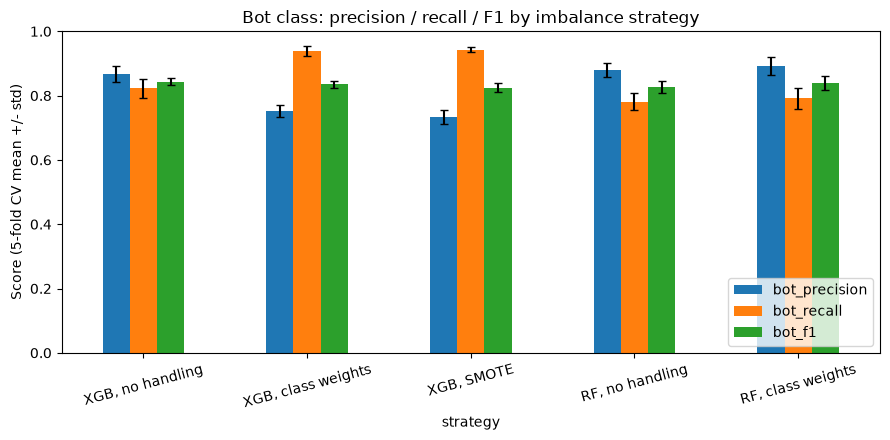

In [5]:
cv_summary.round(5).to_csv(REPORTS_DIR / "results_imbalance_cv.csv")

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_df = cv_summary.xs("mean", axis=1, level=1)[["bot_precision", "bot_recall", "bot_f1"]]
err = cv_summary.xs("std", axis=1, level=1)[["bot_precision", "bot_recall", "bot_f1"]]
plot_df.plot.bar(yerr=err, ax=ax, capsize=3, rot=15)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Score (5-fold CV mean +/- std)")
ax.set_title("Bot class: precision / recall / F1 by imbalance strategy")
ax.legend(loc="upper center", ncol=3, frameon=False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "imbalance_strategies.png", dpi=150)
plt.show()

**Choosing a strategy.** We pick the one with the highest mean **Bot F1** in
cross-validation. F1 balances catching bots (recall) against false alarms
(precision), so a strategy that "catches" bots by flagging lots of benign
traffic does not win.

In [6]:
best_name = cv_summary[("bot_f1", "mean")].idxmax()
best_build, best_weighted = STRATEGIES[best_name]
print("Best strategy:", best_name)

Best strategy: XGB, no handling


### Test-set check: baseline vs best strategy

In [7]:
test_rows = {}
for name in dict.fromkeys(["XGB, no handling", best_name]):
    build, weighted = STRATEGIES[name]
    model = fit(build, weighted, X_train, y_train)
    pred = model.predict(X_test)
    test_rows[name] = evaluate(y_test, pred)
    if name == best_name:
        best_model, best_pred = model, pred

test_imbalance = pd.DataFrame(test_rows).T
test_imbalance.round(4)

,macro_f1,bot_precision,bot_recall,bot_f1,bot_missed,false_bot_alarms
"XGB, no handling",0.9558,0.854,0.7969,0.8245,79.0,53.0


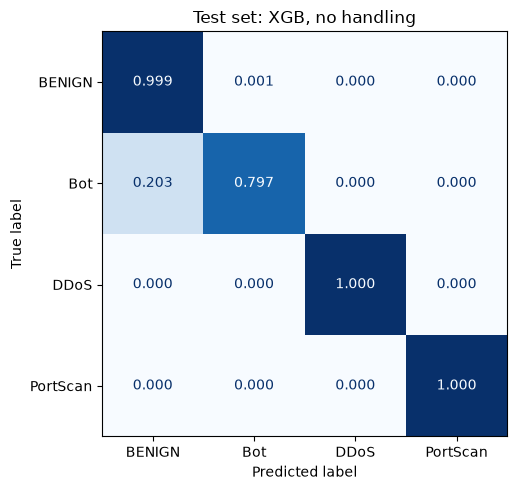

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=classes,
                                        normalize="true", values_format=".3f",
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"Test set: {best_name}")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix_best.png", dpi=150)
plt.show()

## 4. Feature selection

Three ways to rank or filter the 67 features. **All are computed on the
training set only.**

| Method | Type | Idea |
|---|---|---|
| Correlation filter | filter, unsupervised | drop one feature of every pair with \|r\| > 0.95 |
| Mutual information | filter, supervised | how much each feature alone tells us about the label |
| Random Forest importance | embedded | how much each feature helps the trees split |

For the two rankings we then train the chosen model on the top-k features
for several k and see where performance stops improving.

In [9]:
# 1) Correlation filter: keep a feature only if it is not highly correlated with one already kept.
sample = X_train.sample(min(len(X_train), 100_000), random_state=RANDOM_STATE)
corr = sample.corr().abs().fillna(0)
corr_kept = []
for f in feats:
    if all(corr.loc[f, k] <= 0.95 for k in corr_kept):
        corr_kept.append(f)
print(f"Correlation filter keeps {len(corr_kept)} of {len(feats)} features")

Correlation filter keeps 42 of 67 features


In [10]:
# 2) Mutual information (on a stratified sample of 100k training flows, for speed).
_, X_mi, _, y_mi = train_test_split(X_train, y_train, test_size=min(100_000, len(X_train) // 2),
                                    stratify=y_train, random_state=RANDOM_STATE)
t0 = time.perf_counter()
mi = pd.Series(mutual_info_classif(X_mi, y_mi, random_state=RANDOM_STATE), index=feats)
print(f"MI computed in {time.perf_counter() - t0:.0f}s")

# 3) Random Forest impurity importance (fit on the full training set).
rf_rank_model = make_rf().fit(X_train, y_train)
rf_imp = pd.Series(rf_rank_model.feature_importances_, index=feats)

rankings = {
    "Mutual information": mi.sort_values(ascending=False).index.tolist(),
    "RF importance": rf_imp.sort_values(ascending=False).index.tolist(),
}
pd.DataFrame({name: r[:15] for name, r in rankings.items()}, index=range(1, 16))

MI computed in 17s


,Mutual information,RF importance
1,Average Packet Size,Fwd Packet Length Mean
2,Subflow Fwd Bytes,Fwd Packet Length Max
3,Total Length of Fwd Packets,Avg Fwd Segment Size
4,Packet Length Mean,Subflow Fwd Bytes
5,Destination Port,Average Packet Size
6,Packet Length Variance,Bwd Packet Length Mean
7,Packet Length Std,Total Length of Fwd Packets
8,Fwd Packet Length Mean,Bwd Packet Length Max
9,Avg Fwd Segment Size,Avg Bwd Segment Size
10,Fwd Packet Length Max,Bwd Packet Length Std


Now train the chosen model on the top-k features of each ranking. This is the
most informative plot of the project: it shows how much of the detection
performance survives with a small feature set.

In [11]:
K_VALUES = [k for k in [3, 5, 10, 15, 20, 30] if k < len(feats)] + [len(feats)]

fs_rows = []
for method, ranking in rankings.items():
    for k in K_VALUES:
        cols = ranking[:k]
        model = fit(best_build, best_weighted, X_train[cols], y_train)
        fs_rows.append({"method": method, "k": k, **evaluate(y_test, model.predict(X_test[cols]))})
        print(f"{method:20s} k={k:3d}  macro-F1={fs_rows[-1]['macro_f1']:.4f}  Bot F1={fs_rows[-1]['bot_f1']:.4f}")

model = fit(best_build, best_weighted, X_train[corr_kept], y_train)
fs_rows.append({"method": "Correlation filter", "k": len(corr_kept),
                **evaluate(y_test, model.predict(X_test[corr_kept]))})

fs = pd.DataFrame(fs_rows)
fs.round(5).to_csv(REPORTS_DIR / "results_feature_selection.csv", index=False)
fs.round(4)

Mutual information   k=  3  macro-F1=0.8746  Bot F1=0.5161


Mutual information   k=  5  macro-F1=0.8900  Bot F1=0.5662


Mutual information   k= 10  macro-F1=0.8900  Bot F1=0.5662


Mutual information   k= 15  macro-F1=0.9512  Bot F1=0.8077


Mutual information   k= 20  macro-F1=0.9574  Bot F1=0.8311


Mutual information   k= 30  macro-F1=0.9595  Bot F1=0.8389


... (5 outputs left out)

RF importance        k= 20  macro-F1=0.9547  Bot F1=0.8201


RF importance        k= 30  macro-F1=0.9520  Bot F1=0.8092


RF importance        k= 67  macro-F1=0.9555  Bot F1=0.8232


,method,k,macro_f1,bot_precision,bot_recall,bot_f1,bot_missed,false_bot_alarms
0,Mutual information,3,0.8746,0.9855,0.3496,0.5161,253,2
1,Mutual information,5,0.8900,0.9935,0.3959,0.5662,235,1
2,Mutual information,10,0.8900,0.9935,0.3959,0.5662,235,1
3,Mutual information,15,0.9512,0.9610,0.6967,0.8077,118,11
4,Mutual information,20,0.9574,0.9929,0.7147,0.8311,111,2
5,Mutual information,30,0.9595,0.9633,0.7429,0.8389,100,11
6,Mutual information,67,0.9554,0.8474,0.7995,0.8228,78,56
7,RF importance,3,0.7499,0.8387,0.3342,0.4779,259,25
8,RF importance,5,0.8804,0.9732,0.3728,0.5390,244,4
9,RF importance,10,0.8842,1.0000,0.3830,0.5539,240,0


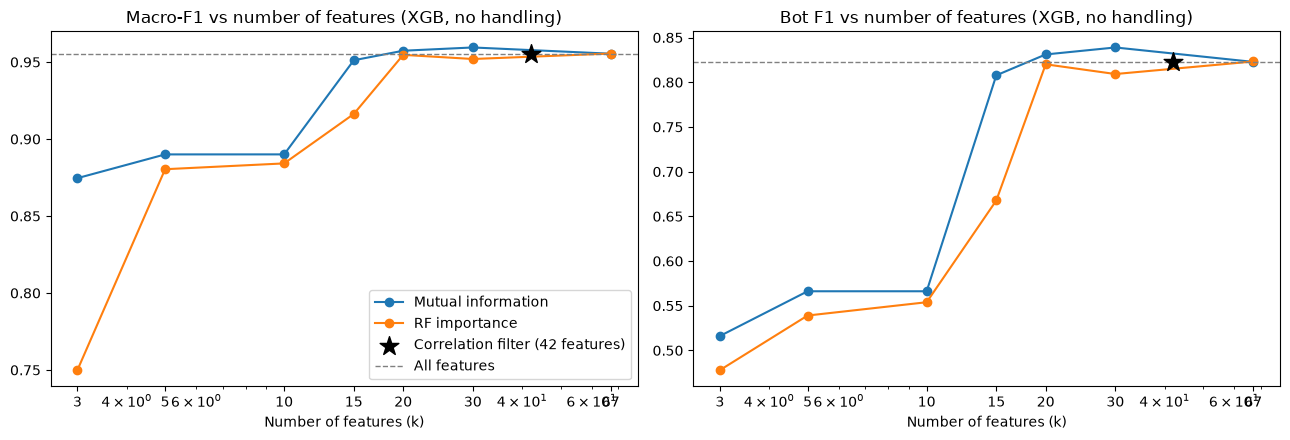

In [12]:
full = fs[(fs["k"] == len(feats))].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, metric, title in zip(axes, ["macro_f1", "bot_f1"], ["Macro-F1", "Bot F1"]):
    for method in rankings:
        part = fs[fs["method"] == method]
        ax.plot(part["k"], part[metric], marker="o", label=method)
    cf = fs[fs["method"] == "Correlation filter"].iloc[0]
    ax.scatter(cf["k"], cf[metric], marker="*", s=200, color="black", zorder=5,
               label=f"Correlation filter ({int(cf['k'])} features)")
    ax.axhline(full[metric], color="grey", ls="--", lw=1, label="All features")
    ax.set_xticks(K_VALUES)
    ax.set_xticklabels(K_VALUES)
    ax.set_xlabel("Number of features (k)")
    ax.set_title(f"{title} vs number of features ({best_name})")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_selection_curve.png", dpi=150)
plt.show()

In [13]:
# Smallest k (from either ranking) that stays within 0.01 Bot F1 and 0.005 macro-F1 of all features.
ranked = fs[fs["method"].isin(rankings.keys())]
good = ranked[(ranked["bot_f1"] >= full["bot_f1"] - 0.01) & (ranked["macro_f1"] >= full["macro_f1"] - 0.005)].sort_values(["k", "bot_f1"], ascending=[True, False])
compact = good.iloc[0]
compact_features = rankings[compact["method"]][: int(compact["k"])]
print(f"Smallest good subset: {int(compact['k'])} features ({compact['method']}), "
      f"Bot F1 {compact['bot_f1']:.4f} vs {full['bot_f1']:.4f} with all {len(feats)}")
compact_features

Smallest good subset: 20 features (Mutual information), Bot F1 0.8311 vs 0.8228 with all 67


['Average Packet Size',
 'Subflow Fwd Bytes',
 'Total Length of Fwd Packets',
 'Packet Length Mean',
 'Destination Port',
 'Packet Length Variance',
 'Packet Length Std',
 'Fwd Packet Length Mean',
 'Avg Fwd Segment Size',
 'Fwd Packet Length Max',
 'Total Length of Bwd Packets',
 'Subflow Bwd Bytes',
 'Init_Win_bytes_forward',
 'Bwd Packet Length Mean',
 'Avg Bwd Segment Size',
 'Fwd Header Length',
 'Bwd Packet Length Max',
 'Init_Win_bytes_backward',
 'Bwd Header Length',
 'Flow Bytes/s']

## 5. Shortcut check: `Destination Port`

In CIC-IDS2017 the bot used a fixed port, so a model could learn "this port =
Bot" instead of learning bot behaviour. That would not transfer to another
network. We retrain the chosen model without the port and compare.

In [14]:
no_port = [f for f in feats if f != "Destination Port"]
port_rows = {}
for label, cols in [("All features", feats), ("Without Destination Port", no_port)]:
    model = fit(best_build, best_weighted, X_train[cols], y_train)
    port_rows[label] = evaluate(y_test, model.predict(X_test[cols]))
port_check = pd.DataFrame(port_rows).T
port_check.round(5).to_csv(REPORTS_DIR / "results_port_ablation.csv")
port_check.round(4)

,macro_f1,bot_precision,bot_recall,bot_f1,bot_missed,false_bot_alarms
All features,0.9558,0.8540,0.7969,0.8245,79.0,53.0
Without Destination Port,0.9543,0.8524,0.7866,0.8182,83.0,53.0


In [15]:
for name, ranking in rankings.items():
    pos = ranking.index("Destination Port") + 1
    print(f"Destination Port rank in {name}: {pos} of {len(ranking)}")

Destination Port rank in Mutual information: 5 of 67
Destination Port rank in RF importance: 15 of 67


## 6. Observations (fill in after running)

- Best imbalance strategy and its effect on Bot recall / false alarms: ...
- Smallest feature subset that keeps performance: ...
- Destination Port dependence: ...